In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

date_columns = ["last_scraped", "calendar_last_scraped", "first_review", "last_review"]

listings = pd.read_csv("data/listings_clean.csv", parse_dates=date_columns)

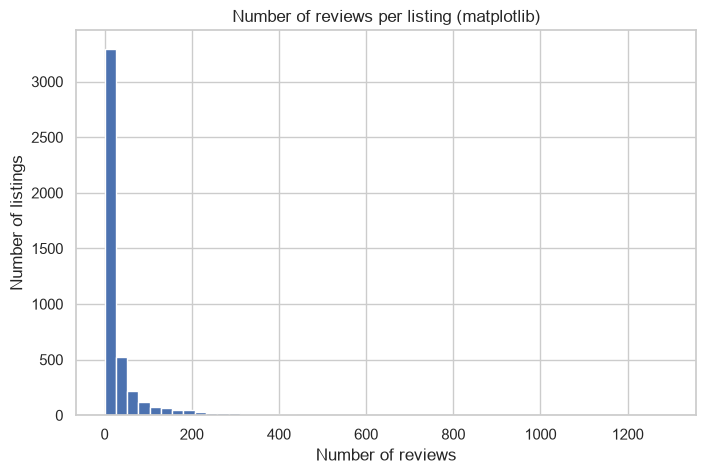

In [18]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(listings["number_of_reviews"], bins=50)

ax.set_title("Number of reviews per listing (matplotlib)")
ax.set_xlabel("Number of reviews")
ax.set_ylabel("Number of listings")

plt.show()

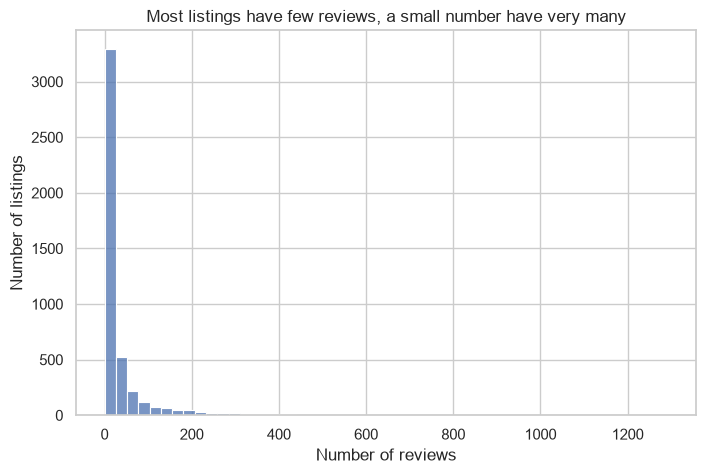

In [19]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=listings, x="number_of_reviews", bins=50, ax=ax)
ax.set_title("Most listings have few reviews, a small number have very many")
ax.set_xlabel("Number of reviews")
ax.set_ylabel("Number of listings")
plt.show()

In [ ]:
reviews = listings["number_of_reviews"]

median = reviews.median()
mean = reviews.mean()
q1 = reviews.quantile(0.25)
q3 = reviews.quantile(0.75)
fence = q3 + 1.5 * (q3 - q1)

print(f"median: {median}, mean: {mean:.1f}, upper fence: {fence}")

fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=listings, x="number_of_reviews", bins=50, ax=ax)
ax.axvline(median, color="black", linestyle="--", label=f"median ({median:.0f})")
ax.axvline(mean, color="red", linestyle="--", label=f"mean ({mean:.0f})")
ax.axvline(fence, color="orange", linestyle="--", label=f"upper fence ({fence:.0f})")
ax.set_title("The mean is pulled right by a few listings with very many reviews")
ax.set_xlabel("Number of reviews")
ax.set_ylabel("Number of listings")
ax.legend()
plt.show()